<a href="https://colab.research.google.com/github/7mid056/synthetic_employee_burnout/blob/main/synthetic_employee_burnout.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [180]:
import kagglehub
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Download latest version
path = kagglehub.dataset_download("ankam6010/synthetic-hr-burnout-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'synthetic-hr-burnout-dataset' dataset.
Path to dataset files: /kaggle/input/synthetic-hr-burnout-dataset


In [181]:
csv_path = os.path.join(path,"synthetic_employee_burnout.csv")

df = pd.read_csv(csv_path)
df.head()

,Name,Age,Gender,JobRole,Experience,WorkHoursPerWeek,RemoteRatio,SatisfactionLevel,StressLevel,Burnout
0,Max Ivanov,32,Male,Analyst,3,60,21,4.40,1,0
1,Max Wang,40,Female,Engineer,9,47,67,2.09,2,0
2,Nina Petrov,33,Female,Engineer,2,44,20,2.58,3,0
3,John Ivanov,35,Female,Manager,6,44,70,3.23,8,0
4,John Wang,59,Male,Sales,8,38,46,4.41,1,0


In [182]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               2000 non-null   object 
 1   Age                2000 non-null   int64  
 2   Gender             2000 non-null   object 
 3   JobRole            2000 non-null   object 
 4   Experience         2000 non-null   int64  
 5   WorkHoursPerWeek   2000 non-null   int64  
 6   RemoteRatio        2000 non-null   int64  
 7   SatisfactionLevel  2000 non-null   float64
 8   StressLevel        2000 non-null   int64  
 9   Burnout            2000 non-null   int64  
dtypes: float64(1), int64(6), object(3)
memory usage: 156.4+ KB


In [183]:
df.describe()
# need to scale the data

,Age,Experience,WorkHoursPerWeek,RemoteRatio,SatisfactionLevel,StressLevel,Burnout
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000
mean,40.694500,10.074500,49.588000,49.973000,2.995230,5.43200,0.064500
std,11.286756,9.148267,11.832424,29.151298,1.155431,2.88089,0.245703
min,22.000000,0.000000,30.000000,0.000000,1.000000,1.00000,0.000000
25%,31.000000,3.000000,39.000000,24.000000,2.000000,3.00000,0.000000
50%,41.000000,7.000000,49.000000,49.000000,3.025000,5.00000,0.000000
75%,50.000000,15.000000,60.000000,75.000000,4.000000,8.00000,0.000000
max,60.000000,39.000000,70.000000,100.000000,5.000000,10.00000,1.000000


In [184]:
def check_duplicates(df):
  duplicates = df.duplicated().sum()
  print(duplicates)
check_duplicates(df)




0


In [185]:
#checking for missing values

missing_values = df.isnull().sum()
print(missing_values.sum())


0


Burnout
0    0.9355
1    0.0645
Name: proportion, dtype: float64


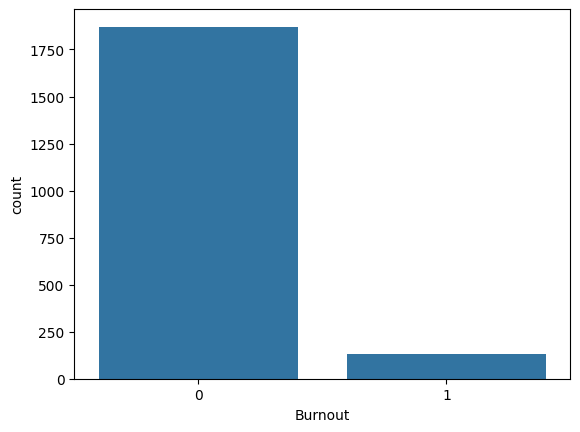

In [186]:
def check_target_imbalance(df, target_column):
  print(df[target_column].value_counts(normalize=True))
  sns.countplot(x=df[target_column])
  plt.show()
check_target_imbalance(df,'Burnout')


#musttt usee skf

In [187]:
#label encoding
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder

le = LabelEncoder()
oe = OneHotEncoder(sparse_output=False)
df['Gender'] =le.fit_transform(df['Gender'])

df['JobRole'] = le.fit_transform(df['JobRole'])


df.head(29)

,Name,Age,Gender,JobRole,Experience,WorkHoursPerWeek,RemoteRatio,SatisfactionLevel,StressLevel,Burnout
0,Max Ivanov,32,1,0,3,60,21,4.40,1,0
1,Max Wang,40,0,1,9,47,67,2.09,2,0
2,Nina Petrov,33,0,1,2,44,20,2.58,3,0
3,John Ivanov,35,0,3,6,44,70,3.23,8,0
4,John Wang,59,1,4,8,38,46,4.41,1,0
5,Lily Smith,45,0,4,11,44,90,4.31,7,0
6,Max Garcia,31,1,4,5,70,30,2.18,3,0
7,Ivan Chen,39,0,2,17,31,53,3.95,4,0
8,Kate Johnson,24,1,0,0,63,35,1.32,5,0
9,Lily Wang,22,1,1,1,30,5,1.44,5,0


In [188]:
df.drop('Name', axis=1, inplace = True)
df
# must identify whether to drop the row or the عامود

,Age,Gender,JobRole,Experience,WorkHoursPerWeek,RemoteRatio,SatisfactionLevel,StressLevel,Burnout
0,32,1,0,3,60,21,4.40,1,0
1,40,0,1,9,47,67,2.09,2,0
2,33,0,1,2,44,20,2.58,3,0
3,35,0,3,6,44,70,3.23,8,0
4,59,1,4,8,38,46,4.41,1,0
...,...,...,...,...,...,...,...,...,...
1995,41,0,3,4,63,17,3.40,4,0
1996,23,0,2,2,39,20,4.67,9,0
1997,31,0,2,10,39,4,4.10,4,0
1998,25,1,2,0,40,57,2.11,4,0


In [189]:
#scale the df
# StandardScaler
from sklearn.preprocessing import StandardScaler

numerical_col = df.columns.drop('Burnout')

scale = StandardScaler()
df[numerical_col] = scale.fit_transform(df[numerical_col])
df.head()

,Age,Gender,JobRole,Experience,WorkHoursPerWeek,RemoteRatio,SatisfactionLevel,StressLevel,Burnout
0,-0.770520,0.977259,-1.406647,-0.773509,0.880175,-0.994132,1.216101,-1.538798,0
1,-0.061548,-1.023271,-0.701384,-0.117483,-0.218776,0.584237,-0.783652,-1.191597,0
2,-0.681899,-1.023271,-0.701384,-0.882847,-0.472380,-1.028445,-0.359462,-0.844395,0
3,-0.504656,-1.023271,0.709142,-0.445496,-0.472380,0.687174,0.203239,0.891614,0
4,1.622262,0.977259,1.414405,-0.226821,-0.979588,-0.136323,1.224758,-1.538798,0


In [190]:
df.describe()

,Age,Gender,JobRole,Experience,WorkHoursPerWeek,RemoteRatio,SatisfactionLevel,StressLevel,Burnout
count,2.000000e+03,2.000000e+03,2.000000e+03,2.000000e+03,2.000000e+03,2.000000e+03,2.000000e+03,2.000000e+03,2000.000000
mean,1.900702e-16,9.325873e-17,2.176037e-17,-4.263256e-17,-7.815970e-17,3.241851e-17,1.403322e-16,-1.083578e-16,0.064500
std,1.000250e+00,1.000250e+00,1.000250e+00,1.000250e+00,1.000250e+00,1.000250e+00,1.000250e+00,1.000250e+00,0.245703
min,-1.656736e+00,-1.023271e+00,-1.406647e+00,-1.101522e+00,-1.655865e+00,-1.714692e+00,-1.727259e+00,-1.538798e+00,0.000000
25%,-8.591418e-01,-1.023271e+00,-7.013843e-01,-7.735092e-01,-8.950531e-01,-8.911952e-01,-8.615647e-01,-8.443948e-01,0.000000
50%,2.707389e-02,9.772585e-01,3.878948e-03,-3.361586e-01,-4.970639e-02,-3.338594e-02,2.577171e-02,-1.499912e-01,0.000000
75%,8.246681e-01,9.772585e-01,7.091422e-01,5.385426e-01,8.801750e-01,8.587357e-01,8.698235e-01,8.916142e-01,0.000000
max,1.710884e+00,9.772585e-01,1.414405e+00,3.162646e+00,1.725522e+00,1.716545e+00,1.735518e+00,1.586018e+00,1.000000


In [191]:
X = df.drop('Burnout', axis =1)
y = df['Burnout']

In [192]:
def sigmoid(z):
  return 1/(1+ np.exp(-z))

In [193]:
def binary_cross_entropy(y,y_hat):
  epsilon = 1e-15
  y_hat = np.clip(y_hat,epsilon, 1- epsilon)
  loss = -1/len(y) * np.sum(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))
  return loss

In [194]:
def gradient_descent(X, y, learning_rate, n_iters=500):
  m, n = X.shape # m rows, n columns (dimensions)
  theta = np.zeros(n) # initialize a zeros weight vector with n dimensions
  losses = []

  for _ in tqdm(range(n_iters), desc="Training Logistic Regression"):
    z = np.dot(X, theta)
    y_hat = sigmoid(z)
    gradient = np.dot(X.T, (y_hat - y)) / m
    theta -= learning_rate * gradient

    loss = binary_cross_entropy(y, y_hat)
    losses.append(loss)

  return theta, losses

In [195]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [196]:
n_splits = 5 # K=5 Folds

# Stratified 5-Fold Cross-Validation, shuffled
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

In [197]:
lr_losses    = []
lr_accuracy  = []
lr_precision = []
lr_recall    = []
lr_f1        = []

In [198]:
for fold_idx, (train_index, test_index) in enumerate(skf.split(X, y)):
    print(f"\nFold {fold_idx + 1}/{n_splits}")

    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]
    # Train
    theta, losses = gradient_descent(X_train, y_train, learning_rate=0.3, n_iters=300)

    # Validate
    y_pred_proba = sigmoid(np.dot(X_test, theta))
    y_pred = (y_pred_proba >= 0.5).astype(int)

    # Calculate evaluation metrics
    accuracy  = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall    = recall_score(y_test, y_pred, zero_division=0)
    f1        = f1_score(y_test, y_pred, zero_division=0)
    # Store results
    lr_losses.append(losses)
    lr_accuracy.append(accuracy)
    lr_precision.append(precision)
    lr_recall.append(recall)
    lr_f1.append(f1)


Fold 1/5


Training Logistic Regression: 100%|██████████| 300/300 [00:00<00:00, 1331.93it/s]



Fold 2/5


Training Logistic Regression: 100%|██████████| 300/300 [00:00<00:00, 1379.95it/s]



Fold 3/5


Training Logistic Regression: 100%|██████████| 300/300 [00:00<00:00, 1381.81it/s]



Fold 4/5


Training Logistic Regression: 100%|██████████| 300/300 [00:00<00:00, 1439.17it/s]



Fold 5/5


Training Logistic Regression: 100%|██████████| 300/300 [00:00<00:00, 1376.82it/s]


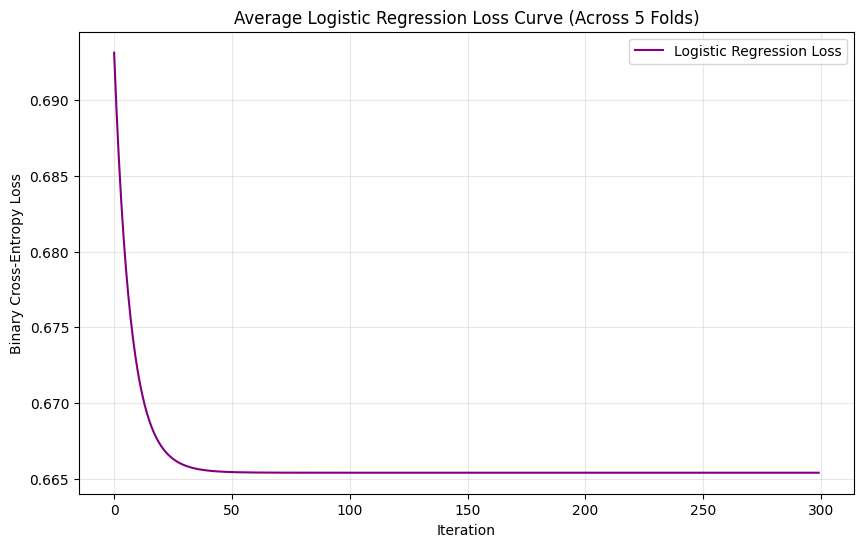

In [203]:
avg_loss = np.mean(lr_losses, axis=0)
plt.figure(figsize=(10, 6))
plt.plot(avg_loss, label='Logistic Regression Loss', color='purple')
plt.title('Average Logistic Regression Loss Curve (Across 5 Folds)')
plt.xlabel('Iteration')
plt.ylabel('Binary Cross-Entropy Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [207]:
print("LOGISTIC REGRESSION Performance:")
print(f"  Accuracy:  {np.mean(lr_accuracy):.4f}")
print(f"  Precision: {np.mean(lr_precision):.4f}")
print(f"  Recall:    {np.mean(lr_recall):.4f}")
print(f"  F1-Score:  {np.mean(lr_f1):.4f}")

LOGISTIC REGRESSION Performance:
  Accuracy:  0.5540
  Precision: 0.1267
  Recall:    1.0000
  F1-Score:  0.2248
